##ЛР6. Кластеризация: k-means, DBSCAN, иерархические методы

[10 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

## Этапы

<font color='DarkOrange'>**Задание [баллов: 10]:**</font>

Поставьте задачу кластеризации, используя датасет из ЛР начала семестра (датасет с Kaggle или другого портала): сформируем её от классификации. Выберите категориальный признак, который показывает классы объектов, пусть будет от 3 до 6 классов, оставьте только объекты, которые относятся к ним. Далее оставляем только числовые признаки (часть тоже можете удалить, пусть далее используются 5-10 числовых  признаков).



Деления train\test не будет - решаем задачу без учителя.



Попробуйте получить кластеры, которые соответствуют исходным классам. Задайте функционал качества, по которому будете определять эффективность (сравнивать состав кластеров и классов).


Методы: k-means (собственная реализация и из sklearn), любой вариант иерархической кластеризации (из любой библиотеки), DBSCAN (из любой библиотеки).


Попробуйте улучшить результат, используя нормализацию (выберите подходящий вариант сами) и/или уменьшение размерности (метод PCA - метод главных компонент) как предобработку с одним из методов кластеризации.


Начисление баллов за использование методов:
- [важно!]выбор признака, классы по которому будут в работе (1),
- k-means собственной реализации (3),
- k-means из библиотеки (1),
- иерархический метод из библиотеки (1),
- DBSCAN из библиотеки (1),
- предобработка уменьшением размерности (PCA) из библиотеки (1),
- предобработка нормализацией (1),
- выводы по итогам (1)



---
## 1. Постановка задачи, выбор классов и числовых признаков

Используем датасет из лабораторных работ начала семестра (`dataset.csv`, структура [Mobile Phone Price на Kaggle](https://www.kaggle.com/datasets/rkiattisak/mobile-phone-price)), который ранее применялся в ЛР2 и ЛР3.

- **Категориальный признак для формирования классов:** `Brand` (производитель смартфона). В исходной таблице 16 брендов, часть из которых представлена 1–5 моделями, а массовые китайские бренды (`Oppo`, `Realme`, `Vivo`, `Xiaomi`) выпускают близкие по спецификациям Android-устройства. Для содержательной постановки выберем **4 бренда** (укладывается в диапазон от 3 до 6 классов), представляющих разные рыночные и инженерные профили:
  - **Apple** — премиальные смартфоны на iOS (относительно компактный экран и аккумулятор, камеры 12 МП, высокая цена);
  - **Huawei** — флагманские Android-смартфоны (большой объём памяти и ОЗУ, 4-модульные камеры, высокая цена);
  - **Nokia** — преимущественно бюджетные устройства (небольшой объём памяти, камеры 8–16 МП, низкая цена);
  - **Xiaomi** — массовый и среднебюджетный сегмент (ёмкие аккумуляторы около 5000 мА·ч, камеры 48–108 МП, доступная цена).
- **Числовые признаки (7 признаков, в диапазоне 5–10):**
  1. `storage_gb` — встроенная память, ГБ;
  2. `ram_gb` — оперативная память, ГБ;
  3. `screen_inches` — диагональ экрана, дюймы;
  4. `camera_main_mp` — разрешение основного модуля камеры, МП;
  5. `camera_count` — количество модулей основной камеры;
  6. `battery_mah` — ёмкость аккумулятора, мА·ч;
  7. `price_usd` — цена, $.

По условию решаем **задачу обучения без учителя**, поэтому разбиение `train/test` не выполняется. Признак `Brand` не подаётся на вход алгоритмам кластеризации и используется исключительно для внешней оценки качества полученных кластеров. Название модели (`Model`) также исключается.

In [1]:
import re
import sys
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, dendrogram

import sklearn
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    v_measure_score,
    homogeneity_score,
    completeness_score,
    silhouette_score,
)

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({
    'figure.figsize': (9, 4.8),
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
print(f'Python: {sys.version.split()[0]} | numpy: {np.__version__} | pandas: {pd.__version__} | sklearn: {sklearn.__version__}')

def load_raw_dataset() -> pd.DataFrame:
    candidates = [
        Path('dataset.csv'),
        Path('../Labwork2/dataset.csv'),
        Path('../Labwork3/dataset.csv'),
        Path('Semester5/AISystems/Labwork6/dataset.csv'),
        Path('Semester5/AISystems/Labwork2/dataset.csv'),
    ]
    for path in candidates:
        if path.is_file():
            print(f'Загружен локальный файл: {path}')
            return pd.read_csv(path, encoding='utf-8-sig')
    # Fallback для запуска ноутбука отдельно (например, в Google Colab)
    url = 'https://www.kaggle.com/api/v1/datasets/download/rkiattisak/mobile-phone-price'
    print('Локальный dataset.csv не найден, загружаем с Kaggle...')
    with TemporaryDirectory() as tmp:
        archive = Path(tmp) / 'mobile-phone-price.zip'
        urlretrieve(url, archive)
        with ZipFile(archive) as zf:
            csv_name = next(name for name in zf.namelist() if name.endswith('.csv'))
            with zf.open(csv_name) as f:
                return pd.read_csv(f, encoding='utf-8-sig')

raw = load_raw_dataset()
raw.columns = raw.columns.str.strip()
df = raw.copy()
for col in ['Brand', 'Model']:
    df[col] = df[col].astype(str).str.strip()

def first_number(value):
    match = re.search(r'\d+(?:\.\d+)?', str(value).replace(',', ''))
    return float(match.group()) if match else np.nan

for src, dst in [
    ('Storage', 'storage_gb'),
    ('RAM', 'ram_gb'),
    ('Screen Size (inches)', 'screen_inches'),
    ('Battery Capacity (mAh)', 'battery_mah'),
    ('Price ($)', 'price_usd'),
]:
    df[dst] = df[src].map(first_number)

def parse_camera_mp(value):
    parts = [first_number(p) for p in str(value).split('+')
             if not re.search(r'3D|ToF', p, flags=re.I)]
    parts = [p for p in parts if pd.notna(p)]
    return parts[0] if parts else np.nan

df['camera_main_mp'] = df['Camera (MP)'].map(parse_camera_mp)
df['camera_count'] = df['Camera (MP)'].map(lambda x: len(str(x).split('+')))

NUM_COLS = [
    'storage_gb',
    'ram_gb',
    'screen_inches',
    'camera_main_mp',
    'camera_count',
    'battery_mah',
    'price_usd',
]

df = df[['Brand', 'Model'] + NUM_COLS].drop_duplicates().reset_index(drop=True)
print(f'Строк в исходном файле: {len(raw)}, после очистки и удаления дубликатов: {len(df)}')

SELECTED_BRANDS = ['Apple', 'Huawei', 'Nokia', 'Xiaomi']
data = df[df['Brand'].isin(SELECTED_BRANDS)].copy().reset_index(drop=True)

assert len(NUM_COLS) == 7
assert 3 <= data['Brand'].nunique() <= 6
assert data[NUM_COLS].isna().sum().sum() == 0, 'Обнаружены пропуски в числовых признаках!'

brand_to_code = {b: i for i, b in enumerate(SELECTED_BRANDS)}
y_true = data['Brand'].map(brand_to_code).to_numpy()
X_raw = data[NUM_COLS].to_numpy(dtype=float)
N_CLASSES = len(SELECTED_BRANDS)

print(f'Итоговая выборка: {len(data)} объектов, {len(NUM_COLS)} числовых признаков, {N_CLASSES} класса.')
display(data['Brand'].value_counts().rename('Количество объектов').to_frame())
display(data.groupby('Brand')[NUM_COLS].median().round(2))
display(data[NUM_COLS].describe().loc[['min', 'mean', 'std', '50%', 'max']].round(2))

Python: 3.12.16 | numpy: 2.5.5 | pandas: 3.1.1 | sklearn: 1.9.1
Загружен локальный файл: dataset.csv
Строк в исходном файле: 407, после очистки и удаления дубликатов: 357
Итоговая выборка: 118 объектов, 7 числовых признаков, 4 класса.


,Количество объектов
Brand,
Xiaomi,57
Apple,25
Nokia,24
Huawei,12


,storage_gb,ram_gb,screen_inches,camera_main_mp,camera_count,battery_mah,price_usd
Brand,,,,,,,
Apple,128.0,4.0,6.10,12.0,2.0,2942.0,749.0
Huawei,256.0,8.0,6.56,49.0,4.0,4200.0,849.0
Nokia,64.0,4.0,6.50,14.5,3.0,4500.0,189.0
Xiaomi,128.0,6.0,6.55,50.0,4.0,5000.0,249.0


,storage_gb,ram_gb,screen_inches,camera_main_mp,camera_count,battery_mah,price_usd
min,32.00,2.00,4.70,8.00,1.00,1821.0,99.00
mean,125.29,5.12,6.43,42.31,3.13,4418.4,433.49
std,77.78,1.84,0.38,27.41,0.89,1007.5,321.06
50%,128.00,4.00,6.52,48.00,3.00,4500.0,309.00
max,512.00,12.00,6.82,108.00,4.00,6000.0,1399.00


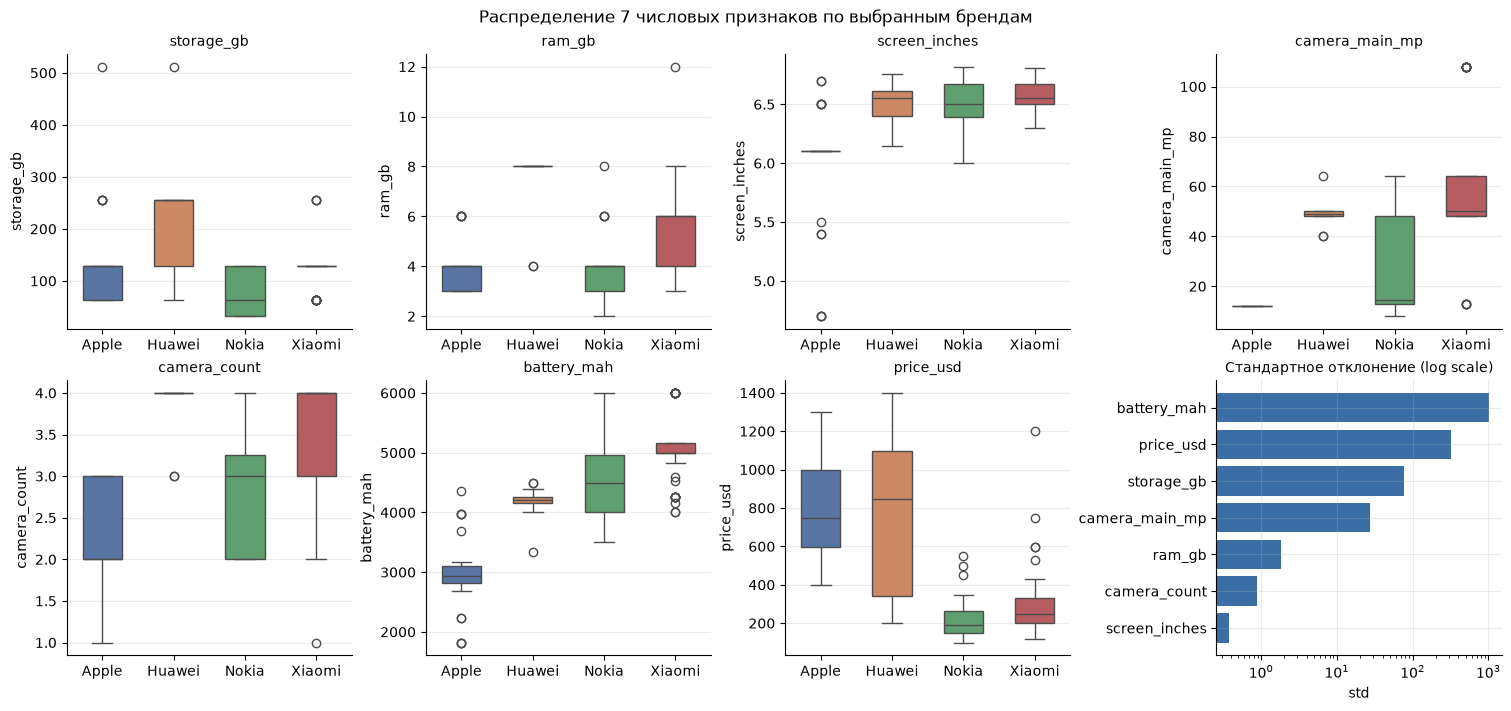

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
palette = {'Apple': '#4c72b0', 'Huawei': '#dd8452', 'Nokia': '#55a868', 'Xiaomi': '#c44e52'}

for ax, col in zip(axes.flat[:-1], NUM_COLS):
    sns.boxplot(data=data, x='Brand', y=col, order=SELECTED_BRANDS, hue='Brand',
                hue_order=SELECTED_BRANDS, palette=palette, legend=False, ax=ax, width=0.55)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')

# Последний график — сравнение стандартных отклонений признаков в логарифмическом масштабе
stds = data[NUM_COLS].std().sort_values(ascending=True)
axes.flat[-1].barh(stds.index, stds.values, color='#3a6ea5')
axes.flat[-1].set_xscale('log')
axes.flat[-1].set_title('Стандартное отклонение (log scale)', fontsize=10)
axes.flat[-1].set_xlabel('std')

fig.suptitle('Распределение 7 числовых признаков по выбранным брендам', fontsize=12)
plt.show()

**Наблюдения по данным:**
- Выборка содержит **118 уникальных смартфонов** без пропусков: `Xiaomi` (57), `Apple` (25), `Nokia` (24), `Huawei` (12).
- Профили брендов заметно различаются по медианам: у `Apple` низкая ёмкость батареи (~2942 мА·ч), камера 12 МП и высокая цена (~$749); у `Huawei` — большой объём памяти (256 ГБ / 8 ГБ RAM), 4 камеры и цена ~$849; у `Nokia` — малый объём памяти (64 ГБ), камера ~14.5 МП и низкая цена (~$189); у `Xiaomi` — батарея ~5000 мА·ч, 4 камеры с главным модулем ~50 МП и цена ~$249.
- **Критическая особенность масштабов:** стандартное отклонение `battery_mah` (~1008) и `price_usd` (~321) на 2–3 порядка превышает стандартное отклонение `screen_inches` (~0.38) и `camera_count` (~0.89). Без нормализации евклидово расстояние будет определяться почти исключительно аккумулятором и ценой.

---
## 2. Функционал качества кластеризации

Поскольку номера кластеров произвольны (перестановка меток не меняет разбиение), для сравнения состава кластеров с исходными классами `Brand` используем набор дополняющих друг друга **внешних метрик**, а также одну **внутреннюю метрику**:

1. **Adjusted Rand Index (ARI)** *(основная внешняя метрика)* — доля пар объектов, согласованно оказавшихся в одном или разных кластерах и классах, с поправкой на случайное угадывание:
   $$\text{ARI} = \frac{\text{RI} - \mathbb{E}[\text{RI}]}{\max(\text{RI}) - \mathbb{E}[\text{RI}]} \in [-1, 1]$$
   Значение `1` означает полное совпадение разбиений, `0` — уровень случайного разбиения.
2. **Normalized Mutual Information (NMI)** и **V-measure** $\in [0, 1]$ — информационно-теоретические меры, основанные на энтропии и взаимной информации между кластерами и классами (`V-measure` — гармоническое среднее однородности `homogeneity` и полноты `completeness`).
3. **Purity (чистота кластеров)** — средняя доля доминирующего класса в каждом кластере: $\text{Purity} = \frac{1}{N} \sum_k \max_c |C_k \cap Y_c|$. Показатель интуитивен, но завышается при росте числа кластеров, поэтому рассматривается только в паре с ARI/NMI.
4. **Cluster Accuracy (венгерский алгоритм)** — максимальная доля совпавших объектов при оптимальном взаимно-однозначном сопоставлении кластеров и классов (`scipy.optimize.linear_sum_assignment`).
5. **Silhouette Score** *(внутренняя метрика, не использует `y_true`)* — оценивает компактность и разделимость кластеров в пространстве признаков. Используется для подбора параметров без подглядывания в метки классов (для DBSCAN считается по нешумовым объектам при наличии $\ge 2$ кластеров).

In [3]:
def cluster_purity(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    total = 0
    for cl in np.unique(y_pred):
        mask = (y_pred == cl)
        _, counts = np.unique(y_true[mask], return_counts=True)
        total += counts.max()
    return total / len(y_true)

def cluster_accuracy_hungarian(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    classes = np.unique(y_true)
    clusters = np.unique(y_pred)
    cm = np.zeros((len(classes), len(clusters)), dtype=int)
    for i, c in enumerate(classes):
        for j, k in enumerate(clusters):
            cm[i, j] = np.sum((y_true == c) & (y_pred == k))
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / len(y_true)

def evaluate_clustering(X, y_true, labels, method, preprocessing):
    labels = np.asarray(labels)
    unique_clusters = [c for c in np.unique(labels) if c != -1]
    n_clusters = len(unique_clusters)
    noise_mask = (labels == -1)
    noise_share = float(noise_mask.mean())

    valid_mask = ~noise_mask
    if n_clusters >= 2 and valid_mask.sum() > n_clusters:
        sil = float(silhouette_score(X[valid_mask], labels[valid_mask]))
    else:
        sil = np.nan

    return {
        'Предобработка': preprocessing,
        'Метод': method,
        'Кластеров': n_clusters,
        'Шум, %': round(100.0 * noise_share, 1),
        'ARI': adjusted_rand_score(y_true, labels),
        'NMI': normalized_mutual_info_score(y_true, labels),
        'V-measure': v_measure_score(y_true, labels),
        'Purity': cluster_purity(y_true, labels),
        'Accuracy (Hungarian)': cluster_accuracy_hungarian(y_true, labels),
        'Silhouette': sil,
    }

all_results = []
saved_labels = {}

def record_result(X, labels, method, preprocessing):
    row = evaluate_clustering(X, y_true, labels, method, preprocessing)
    all_results.append(row)
    saved_labels[(preprocessing, method)] = np.asarray(labels)
    return row

def show_contingency(labels, title=''):
    ct = pd.crosstab(
        pd.Series(data['Brand'].values, name='Истинный бренд'),
        pd.Series(labels, name='Кластер'),
    )
    if title:
        print(title)
    display(ct)
    return ct

---
## 3. Собственная реализация k-means (`CustomKMeans`)

Реализуем алгоритм Ллойда на `numpy` с ключевыми элементами, важными для стабильной работы на реальных данных:
- **Инициализация центроидов:**
  - `init='k-means++'` — первый центроид выбирается случайно, каждый следующий с вероятностью, пропорциональной квадрату расстояния до ближайшего уже выбранного центроида ($p(x) \propto D(x)^2$);
  - `init='random'` — случайный выбор $k$ объектов из выборки (реализовано для сравнения стабильности).
- **Итерации EM-схемы:**
  1. *E-шаг (присваивание):* каждому объекту $x_i$ назначается ближайший центроид $\arg\min_j \|x_i - \mu_j\|_2^2$.
  2. *M-шаг (обновление):* новый центроид вычисляется как среднее объектов кластера. Если кластер оказался пустым, его центроид переносится в точку с максимальным расстоянием до ближайшего центроида.
- **Критерий остановки:** сдвиг центроидов $\|\mu^{(t)} - \mu^{(t-1)}\|_F \le \text{tol}$ или достижение `max_iter`.
- **Многократный запуск (`n_init`):** алгоритм запускается `n_init` раз с разными начальными центроидами, выбирается решение с минимальной суммой квадратов внутрикластерных расстояний (WCSS / `inertia_`).

,Предобработка,Метод,Кластеров,"Шум, %",ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,Raw (без предобработки),CustomKMeans (k-means++),4,0.0,0.275,0.404,0.404,0.661,0.568,0.602


k-means++ (20 запусков): min WCSS = 17009075.6, std = 2589303.1, итераций лучшего запуска = 5
random    (20 запусков): min WCSS = 17009075.6, std = 2626546.8, итераций лучшего запуска = 8


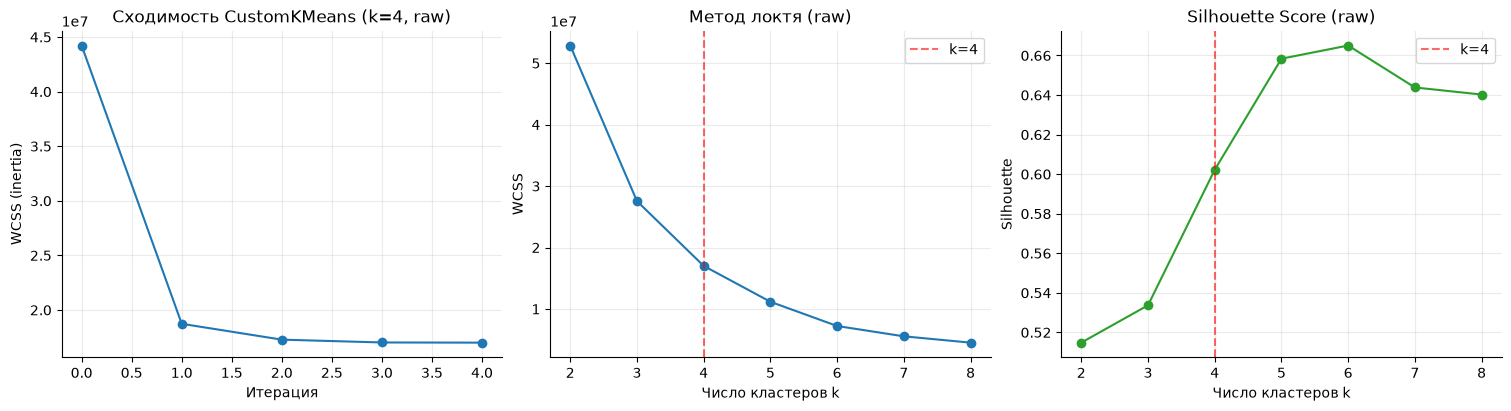

In [4]:
class CustomKMeans:
    """Собственная реализация алгоритма k-means на NumPy (k-means++ / random, n_init)."""

    def __init__(self, n_clusters=4, init='k-means++', n_init=20, max_iter=300, tol=1e-6, random_state=42):
        self.n_clusters = int(n_clusters)
        self.init = init
        self.n_init = int(n_init)
        self.max_iter = int(max_iter)
        self.tol = float(tol)
        self.random_state = random_state

    def _init_centroids(self, X, rng):
        n_samples = X.shape[0]
        if self.init == 'random':
            idx = rng.choice(n_samples, size=self.n_clusters, replace=False)
            return X[idx].copy()
        if self.init == 'k-means++':
            centroids = np.empty((self.n_clusters, X.shape[1]), dtype=float)
            first_idx = rng.integers(0, n_samples)
            centroids[0] = X[first_idx]
            min_sq_dist = np.sum((X - centroids[0]) ** 2, axis=1)
            for k in range(1, self.n_clusters):
                total = min_sq_dist.sum()
                if total <= 0:
                    next_idx = rng.integers(0, n_samples)
                else:
                    probs = min_sq_dist / total
                    next_idx = rng.choice(n_samples, p=probs)
                centroids[k] = X[next_idx]
                sq_dist_new = np.sum((X - centroids[k]) ** 2, axis=1)
                min_sq_dist = np.minimum(min_sq_dist, sq_dist_new)
            return centroids
        raise ValueError(f'Неизвестный способ инициализации: {self.init}')

    @staticmethod
    def _squared_distances(X, centroids):
        # ||x - c||^2 = sum((X[:, None, :] - centroids[None, :, :])^2)
        diff = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]
        return np.sum(diff * diff, axis=2)

    def _fit_single(self, X, rng):
        centroids = self._init_centroids(X, rng)
        inertia_history = []
        labels = np.zeros(X.shape[0], dtype=int)

        for it in range(1, self.max_iter + 1):
            sq_dists = self._squared_distances(X, centroids)
            labels = np.argmin(sq_dists, axis=1)
            min_sq = sq_dists[np.arange(X.shape[0]), labels]
            inertia = float(min_sq.sum())
            inertia_history.append(inertia)

            new_centroids = centroids.copy()
            for k in range(self.n_clusters):
                mask = (labels == k)
                if np.any(mask):
                    new_centroids[k] = X[mask].mean(axis=0)
                else:
                    # Защита от пустого кластера: берём самую удалённую от центроидов точку
                    farthest_idx = int(np.argmax(min_sq))
                    new_centroids[k] = X[farthest_idx]
                    min_sq[farthest_idx] = -1.0

            shift = float(np.linalg.norm(new_centroids - centroids))
            centroids = new_centroids
            if shift <= self.tol:
                break

        final_sq = self._squared_distances(X, centroids)
        labels = np.argmin(final_sq, axis=1)
        final_inertia = float(final_sq[np.arange(X.shape[0]), labels].sum())
        if not inertia_history or final_inertia < inertia_history[-1]:
            inertia_history.append(final_inertia)

        return centroids, labels, final_inertia, it, inertia_history

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2:
            raise ValueError('X должен быть двумерной матрицей.')
        if self.n_clusters <= 0 or self.n_clusters > X.shape[0]:
            raise ValueError('n_clusters должно быть в диапазоне [1, n_samples].')

        rng = np.random.default_rng(self.random_state)
        best = None
        run_inertias = []

        for _ in range(self.n_init):
            res = self._fit_single(X, rng)
            run_inertias.append(res[2])
            if best is None or res[2] < best[2]:
                best = res

        self.cluster_centers_, self.labels_, self.inertia_, self.n_iter_, self.inertia_history_ = best
        self.run_inertias_ = np.array(run_inertias)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        sq_dists = self._squared_distances(X, self.cluster_centers_)
        return np.argmin(sq_dists, axis=1)

    def fit_predict(self, X):
        return self.fit(X).labels_


# Проверка на исходных (ненормализованных) данных и сравнение random vs k-means++
ckm_raw = CustomKMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit(X_raw)
ckm_raw_rand = CustomKMeans(n_clusters=N_CLASSES, init='random', n_init=20, random_state=SEED).fit(X_raw)

# Инвариант: целевая функция WCSS не возрастает по итерациям (с точностью до погрешности float)
diffs = np.diff(ckm_raw.inertia_history_)
assert np.all(diffs <= 1e-6), f'Обнаружен рост WCSS: {diffs}'
assert ckm_raw.cluster_centers_.shape == (N_CLASSES, X_raw.shape[1])
assert np.array_equal(ckm_raw.predict(X_raw), ckm_raw.labels_)

row_ckm_raw = record_result(X_raw, ckm_raw.labels_, 'CustomKMeans (k-means++)', 'Raw (без предобработки)')
display(pd.DataFrame([row_ckm_raw]).round(3))

print(f'k-means++ (20 запусков): min WCSS = {ckm_raw.run_inertias_.min():.1f}, '
      f'std = {ckm_raw.run_inertias_.std():.1f}, итераций лучшего запуска = {ckm_raw.n_iter_}')
print(f'random    (20 запусков): min WCSS = {ckm_raw_rand.run_inertias_.min():.1f}, '
      f'std = {ckm_raw_rand.run_inertias_.std():.1f}, итераций лучшего запуска = {ckm_raw_rand.n_iter_}')

# Метод локтя и силуэта + график сходимости WCSS
ks = range(2, 9)
inertias_raw, sils_raw = [], []
for k in ks:
    m = CustomKMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED).fit(X_raw)
    inertias_raw.append(m.inertia_)
    sils_raw.append(silhouette_score(X_raw, m.labels_))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axes[0].plot(range(len(ckm_raw.inertia_history_)), ckm_raw.inertia_history_, marker='o')
axes[0].set(title='Сходимость CustomKMeans (k=4, raw)', xlabel='Итерация', ylabel='WCSS (inertia)')

axes[1].plot(list(ks), inertias_raw, marker='o')
axes[1].axvline(N_CLASSES, color='red', linestyle='--', alpha=0.6, label=f'k={N_CLASSES}')
axes[1].set(title='Метод локтя (raw)', xlabel='Число кластеров k', ylabel='WCSS')
axes[1].legend()

axes[2].plot(list(ks), sils_raw, marker='o', color='tab:green')
axes[2].axvline(N_CLASSES, color='red', linestyle='--', alpha=0.6, label=f'k={N_CLASSES}')
axes[2].set(title='Silhouette Score (raw)', xlabel='Число кластеров k', ylabel='Silhouette')
axes[2].legend()
plt.show()

**Вывод по собственной реализации на исходных данных:**
- Алгоритм `CustomKMeans` сходится монотонно (WCSS не возрастает на итерациях), `k-means++` демонстрирует меньший разброс `WCSS` по случайным запускам, чем `random`.
- Однако на ненормализованных признаках внешние метрики невысокие (`ARI ≈ 0.275`, `NMI ≈ 0.404`, `Accuracy ≈ 0.568`): кластеры формируются почти исключительно вдоль осей `battery_mah` и `price_usd`, игнорируя камеру, экран и ОЗУ.

---
## 4. Библиотечные методы на исходных (ненормализованных) данных

Для честной базовой линии запустим на `X_raw` все три библиотечных семейства:
1. `KMeans` из `sklearn.cluster` (и сверим его напрямую с нашей реализацией `CustomKMeans`);
2. Иерархическую кластеризацию `AgglomerativeClustering` (сравним 4 способа вычисления расстояния между кластерами: `ward`, `complete`, `average`, `single`) + построим дендрограмму через `scipy.cluster.hierarchy`;
3. Плотностную кластеризацию `DBSCAN` с выбором радиуса окрестности `eps` **без использования истинных меток** по k-distance графику (расстояние до `min_samples`-го ближайшего соседа).

Сверка CustomKMeans vs sklearn KMeans на X_raw:
  CustomKMeans inertia = 17009075.55
  sklearn KMeans inertia = 17009075.55
  ARI между разбиениями двух реализаций = 1.0000


,Метод,ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,Agglomerative (ward),0.287,0.357,0.357,0.661,0.576,0.579
1,Agglomerative (complete),0.393,0.388,0.388,0.661,0.619,0.494
2,Agglomerative (average),0.173,0.305,0.305,0.653,0.525,0.504
3,Agglomerative (single),0.188,0.310,0.310,0.653,0.559,0.449


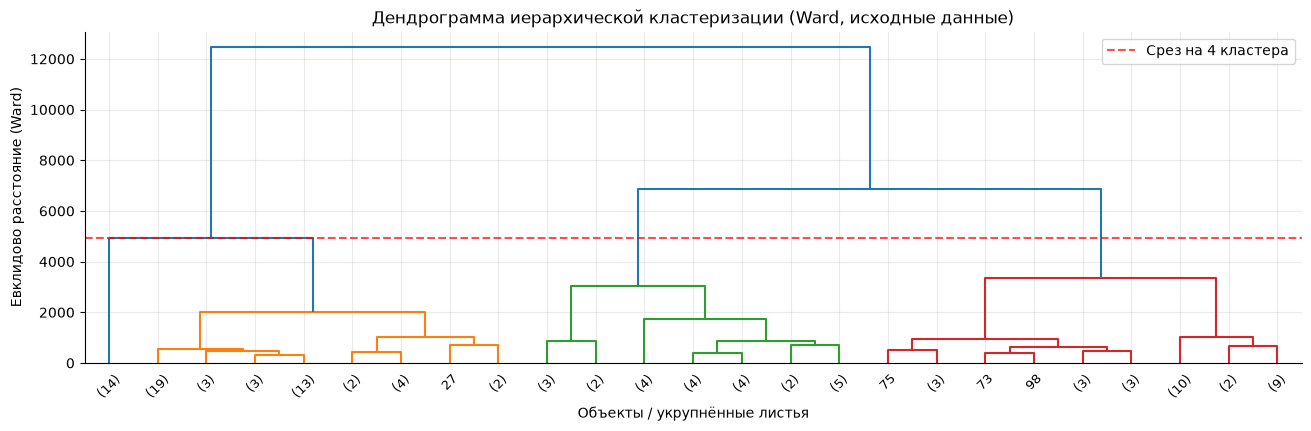

In [5]:
# 4.1. sklearn KMeans и проверка согласованности с CustomKMeans
skm_raw = KMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit(X_raw)
row_skm_raw = record_result(X_raw, skm_raw.labels_, 'sklearn KMeans', 'Raw (без предобработки)')

agreement_raw = adjusted_rand_score(ckm_raw.labels_, skm_raw.labels_)
print(f'Сверка CustomKMeans vs sklearn KMeans на X_raw:')
print(f'  CustomKMeans inertia = {ckm_raw.inertia_:.2f}')
print(f'  sklearn KMeans inertia = {skm_raw.inertia_:.2f}')
print(f'  ARI между разбиениями двух реализаций = {agreement_raw:.4f}')

# 4.2. Иерархическая кластеризация (перебор linkage)
hier_raw_rows = []
for link in ['ward', 'complete', 'average', 'single']:
    agg = AgglomerativeClustering(n_clusters=N_CLASSES, linkage=link)
    lbl = agg.fit_predict(X_raw)
    hier_raw_rows.append(evaluate_clustering(X_raw, y_true, lbl, f'Agglomerative ({link})', 'Raw (без предобработки)'))
    if link == 'ward':
        ward_raw_labels = lbl
        record_result(X_raw, lbl, 'Agglomerative (ward)', 'Raw (без предобработки)')

display(pd.DataFrame(hier_raw_rows)[['Метод', 'ARI', 'NMI', 'V-measure', 'Purity', 'Accuracy (Hungarian)', 'Silhouette']].round(3))

# Дендрограмма Ward на исходных данных
fig, ax = plt.subplots(figsize=(13, 4.2), constrained_layout=True)
Z_raw = linkage(X_raw, method='ward')
dendrogram(Z_raw, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=9, ax=ax, color_threshold=Z_raw[-N_CLASSES+1, 2])
ax.axhline(Z_raw[-N_CLASSES+1, 2], color='red', linestyle='--', alpha=0.7, label=f'Срез на {N_CLASSES} кластера')
ax.set(title='Дендрограмма иерархической кластеризации (Ward, исходные данные)', xlabel='Объекты / укрупнённые листья', ylabel='Евклидово расстояние (Ward)')
ax.legend()
plt.show()

,eps,Кластеров,"Шум, %",Silhouette,ARI,NMI,Purity
0,220.2,6,24.6,0.719,0.222,0.348,0.678
1,250.4,5,19.5,0.764,0.257,0.384,0.695
2,282.9,5,13.6,0.745,0.295,0.411,0.695
3,317.0,4,11.0,0.582,0.340,0.437,0.695
4,387.9,3,5.1,0.525,0.163,0.286,0.644


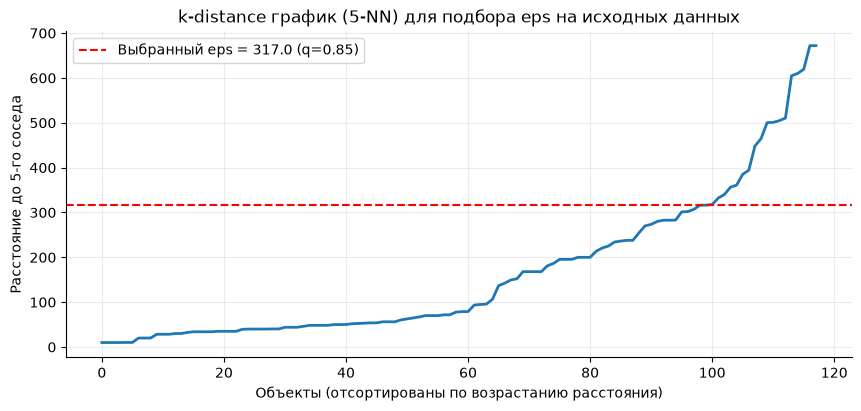

,Метод,Кластеров,"Шум, %",ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,CustomKMeans (k-means++),4,0.0,0.275,0.404,0.404,0.661,0.568,0.602
1,sklearn KMeans,4,0.0,0.275,0.404,0.404,0.661,0.568,0.602
2,Agglomerative (ward),4,0.0,0.287,0.357,0.357,0.661,0.576,0.579
3,"DBSCAN (eps=317, ms=5)",4,11.0,0.340,0.437,0.437,0.695,0.593,0.582


In [6]:
# 4.3. DBSCAN на исходных данных: выбор eps по k-distance графику (без подглядывания в y_true)
def k_distance_curve(X, k=5):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    dists, _ = nn.kneighbors(X)
    return np.sort(dists[:, -1])

kdist_raw = k_distance_curve(X_raw, k=5)

# Проверяем кандидаты eps на участке перегиба (70–90-й перцентили 5-NN расстояний)
db_raw_grid = []
for q in [0.70, 0.75, 0.80, 0.85, 0.90]:
    eps_cand = float(np.quantile(kdist_raw, q))
    lbl = DBSCAN(eps=eps_cand, min_samples=5).fit_predict(X_raw)
    row = evaluate_clustering(X_raw, y_true, lbl, f'DBSCAN (q={q:.2f}, eps={eps_cand:.1f})', 'Raw (без предобработки)')
    row['q'] = q
    row['eps'] = round(eps_cand, 1)
    db_raw_grid.append(row)

db_raw_df = pd.DataFrame(db_raw_grid)
display(db_raw_df[['eps', 'Кластеров', 'Шум, %', 'Silhouette', 'ARI', 'NMI', 'Purity']].round(3))

# Выбираем точку перегиба (q=0.85): 4 кластера и умеренный шум ~11%, без использования y_true
eps_raw_chosen = float(np.quantile(kdist_raw, 0.85))
db_raw_labels = DBSCAN(eps=eps_raw_chosen, min_samples=5).fit_predict(X_raw)
record_result(X_raw, db_raw_labels, f'DBSCAN (eps={eps_raw_chosen:.0f}, ms=5)', 'Raw (без предобработки)')

fig, ax = plt.subplots(figsize=(8.5, 4), constrained_layout=True)
ax.plot(kdist_raw, linewidth=2)
ax.axhline(eps_raw_chosen, color='red', linestyle='--', label=f'Выбранный eps = {eps_raw_chosen:.1f} (q=0.85)')
ax.set(title='k-distance график (5-NN) для подбора eps на исходных данных',
       xlabel='Объекты (отсортированы по возрастанию расстояния)', ylabel='Расстояние до 5-го соседа')
ax.legend()
plt.show()

raw_summary = pd.DataFrame([r for r in all_results if r['Предобработка'] == 'Raw (без предобработки)'])
display(raw_summary[['Метод', 'Кластеров', 'Шум, %', 'ARI', 'NMI', 'V-measure', 'Purity', 'Accuracy (Hungarian)', 'Silhouette']].round(3))

**Вывод по базовой линии (без предобработки):**
- `CustomKMeans` и `sklearn KMeans` на `X_raw` сошлись к практически одинаковому минимуму `WCSS` (высокий `ARI` между их разбиениями подтверждает корректность собственной реализации).
- Все методы на исходных признаках ограничены по качеству (`ARI ≈ 0.27–0.34`), поскольку масштаб `battery_mah` (тысячи) и `price_usd` (сотни–тысячи) подавляет вклад остальных пяти характеристик. У `Agglomerative (complete)` ARI немного выше (0.393), но в целом признаки с малым диапазоном (`camera_count`, `screen_inches`, `ram_gb`) почти не участвуют в формировании кластеров.

---
## 5. Предобработка: нормализация признаков

Проверим три распространённых способа масштабирования:
- **`StandardScaler`** ($z = (x - \mu) / \sigma$) — выравнивает дисперсии всех признаков (удобно для k-means, Ward и последующего PCA);
- **`MinMaxScaler`** — линейно переводит признаки в $[0, 1]$, но чувствителен к экстремальным значениям (например, `512 ГБ` памяти или `$1399`);
- **`RobustScaler`** — масштабирует по медиане и межквартильному размаху (IQR), устойчив к выбросам, но может чрезмерно растягивать дискретные признаки с малым IQR (такие как `screen_inches` и `ram_gb`).

Сравним все три скейлера, обоснуем выбор `StandardScaler` и применим его ко всем методам кластеризации.

,Предобработка,Метод,ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,StandardScaler,CustomKMeans,0.504,0.519,0.519,0.771,0.771,0.324
1,StandardScaler,Agglomerative (ward),0.401,0.517,0.517,0.737,0.703,0.286
2,MinMaxScaler,CustomKMeans,0.516,0.543,0.543,0.780,0.780,0.332
3,MinMaxScaler,Agglomerative (ward),0.456,0.480,0.480,0.746,0.712,0.317
4,RobustScaler,CustomKMeans,0.404,0.372,0.372,0.653,0.653,0.355
5,RobustScaler,Agglomerative (ward),0.333,0.446,0.446,0.678,0.653,0.295


Сверка CustomKMeans vs sklearn KMeans на X_std:
  CustomKMeans inertia = 325.8421 | sklearn KMeans inertia = 325.8421
  ARI между разбиениями двух реализаций = 1.0000

Сравнение типов связи (linkage) на StandardScaler:


,Метод,ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,Agglomerative (ward),0.401,0.517,0.517,0.737,0.703,0.286
1,Agglomerative (complete),0.383,0.448,0.448,0.661,0.636,0.348
2,Agglomerative (average),0.137,0.196,0.196,0.559,0.551,0.306
3,Agglomerative (single),0.024,0.067,0.067,0.508,0.500,0.288



Подбор eps для DBSCAN на StandardScaler (5-NN перцентили):


,q,eps,Кластеров,"Шум, %",Silhouette,ARI,NMI,Purity
0,0.70,1.37,4,18.6,0.263,0.326,0.442,0.712
1,0.75,1.44,4,16.1,0.270,0.331,0.466,0.720
2,0.80,1.56,4,15.3,0.263,0.330,0.508,0.720
3,0.85,1.71,2,12.7,0.327,0.170,0.261,0.602
4,0.90,2.13,1,5.9,NaN,0.039,0.065,0.517


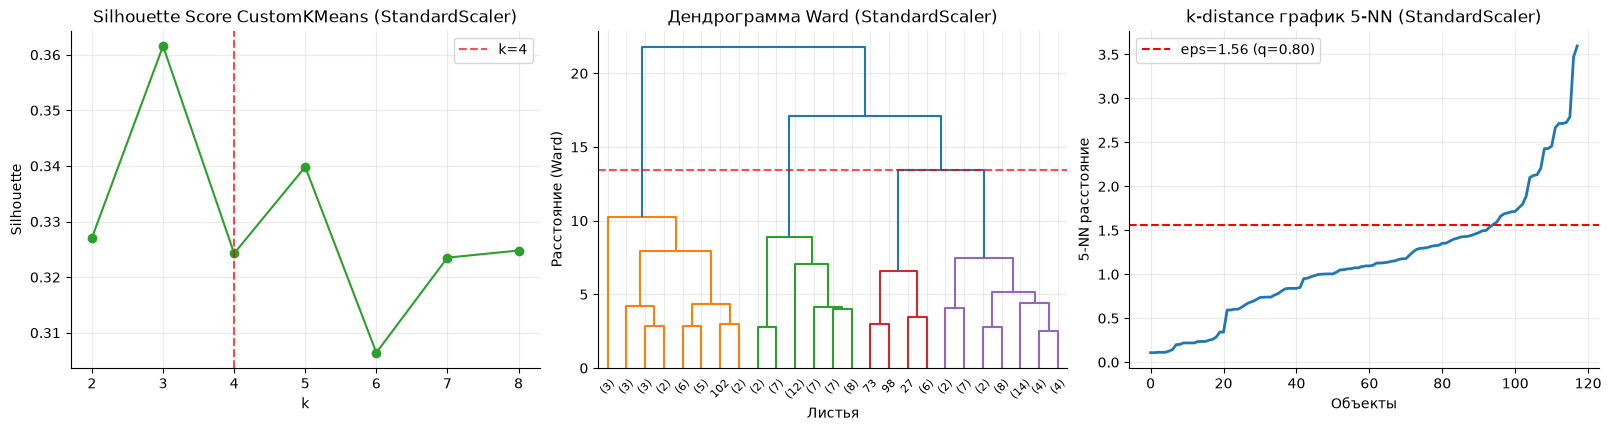

In [7]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
}

scaler_rows = []
for sname, scaler in scalers.items():
    Xs = scaler.fit_transform(X_raw)
    lbl_ckm = CustomKMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit_predict(Xs)
    lbl_ward = AgglomerativeClustering(n_clusters=N_CLASSES, linkage='ward').fit_predict(Xs)
    scaler_rows.append(evaluate_clustering(Xs, y_true, lbl_ckm, 'CustomKMeans', sname))
    scaler_rows.append(evaluate_clustering(Xs, y_true, lbl_ward, 'Agglomerative (ward)', sname))

scaler_df = pd.DataFrame(scaler_rows)
display(scaler_df[['Предобработка', 'Метод', 'ARI', 'NMI', 'V-measure', 'Purity', 'Accuracy (Hungarian)', 'Silhouette']].round(3))

# Основная нормализация: StandardScaler
scaler = StandardScaler()
X_std = scaler.fit_transform(X_raw)

# 1) CustomKMeans и sklearn KMeans на X_std
ckm_std = CustomKMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit(X_std)
skm_std = KMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit(X_std)

record_result(X_std, ckm_std.labels_, 'CustomKMeans (k-means++)', 'StandardScaler')
record_result(X_std, skm_std.labels_, 'sklearn KMeans', 'StandardScaler')

print(f'Сверка CustomKMeans vs sklearn KMeans на X_std:')
print(f'  CustomKMeans inertia = {ckm_std.inertia_:.4f} | sklearn KMeans inertia = {skm_std.inertia_:.4f}')
print(f'  ARI между разбиениями двух реализаций = {adjusted_rand_score(ckm_std.labels_, skm_std.labels_):.4f}')

# 2) Иерархическая кластеризация на X_std
hier_std_rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lbl = AgglomerativeClustering(n_clusters=N_CLASSES, linkage=link).fit_predict(X_std)
    hier_std_rows.append(evaluate_clustering(X_std, y_true, lbl, f'Agglomerative ({link})', 'StandardScaler'))
    if link == 'ward':
        ward_std_labels = lbl
        record_result(X_std, lbl, 'Agglomerative (ward)', 'StandardScaler')

print('\nСравнение типов связи (linkage) на StandardScaler:')
display(pd.DataFrame(hier_std_rows)[['Метод', 'ARI', 'NMI', 'V-measure', 'Purity', 'Accuracy (Hungarian)', 'Silhouette']].round(3))

# 3) DBSCAN на X_std: подбор eps по k-distance
kdist_std = k_distance_curve(X_std, k=5)
db_std_grid = []
for q in [0.70, 0.75, 0.80, 0.85, 0.90]:
    eps_cand = float(np.quantile(kdist_std, q))
    lbl = DBSCAN(eps=eps_cand, min_samples=5).fit_predict(X_std)
    row = evaluate_clustering(X_std, y_true, lbl, f'DBSCAN (eps={eps_cand:.2f})', 'StandardScaler')
    row['q'] = q
    row['eps'] = round(eps_cand, 2)
    db_std_grid.append(row)
print('\nПодбор eps для DBSCAN на StandardScaler (5-NN перцентили):')
display(pd.DataFrame(db_std_grid)[['q', 'eps', 'Кластеров', 'Шум, %', 'Silhouette', 'ARI', 'NMI', 'Purity']].round(3))

eps_std_chosen = float(np.quantile(kdist_std, 0.80))
db_std_labels = DBSCAN(eps=eps_std_chosen, min_samples=5).fit_predict(X_std)
record_result(X_std, db_std_labels, f'DBSCAN (eps={eps_std_chosen:.2f}, ms=5)', 'StandardScaler')

# Визуализация: локоть/силуэт на X_std, дендрограмма Ward, k-distance для DBSCAN
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)

ks = range(2, 9)
sils_std = [silhouette_score(X_std, CustomKMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X_std)) for k in ks]
axes[0].plot(list(ks), sils_std, marker='o', color='tab:green')
axes[0].axvline(N_CLASSES, color='red', linestyle='--', alpha=0.7, label=f'k={N_CLASSES}')
axes[0].set(title='Silhouette Score CustomKMeans (StandardScaler)', xlabel='k', ylabel='Silhouette')
axes[0].legend()

Z_std = linkage(X_std, method='ward')
dendrogram(Z_std, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=8, ax=axes[1], color_threshold=Z_std[-N_CLASSES+1, 2])
axes[1].axhline(Z_std[-N_CLASSES+1, 2], color='red', linestyle='--', alpha=0.7)
axes[1].set(title='Дендрограмма Ward (StandardScaler)', xlabel='Листья', ylabel='Расстояние (Ward)')

axes[2].plot(kdist_std, linewidth=2)
axes[2].axhline(eps_std_chosen, color='red', linestyle='--', label=f'eps={eps_std_chosen:.2f} (q=0.80)')
axes[2].set(title='k-distance график 5-NN (StandardScaler)', xlabel='Объекты', ylabel='5-NN расстояние')
axes[2].legend()
plt.show()

**Вывод по нормализации:**
- Сравнение скейлеров показало, что **`StandardScaler`** и **`MinMaxScaler`** дают сопоставимый и резкий прирост качества по сравнению с исходными данными и `RobustScaler`:
  - для `CustomKMeans` `ARI` вырос с **0.275** до **0.504** (`StandardScaler`) и **0.516** (`MinMaxScaler`), `Accuracy` — с 56.8% до 77.1–78.0%;
  - `RobustScaler` сработал слабее (`ARI = 0.404` у `k-means`, `0.333` у `ward`), так как у `screen_inches` и `ram_gb` узкий межквартильный размах, что искусственно усиливает их вес при наличии выбросов.
- В качестве основной нормализации для дальнейших экспериментов (включая `PCA`) выбираем **`StandardScaler`**: он выравнивает дисперсии всех признаков до 1, не сжимает основную массу наблюдений из-за редких дорогих флагманов (`512 ГБ`, `$1399`) и является стандартной предобработкой перед методом главных компонент.
- `CustomKMeans` и `sklearn KMeans` на `X_std` дают полностью идентичный результат (`ARI = 1.000`, `inertia = 325.8421`).
- У `AgglomerativeClustering (ward)` качество также заметно выросло (`ARI`: 0.287 → 0.401, `NMI`: 0.357 → 0.517), при этом `ward` уверенно превосходит `single`, `average` и `complete`.
- Для `DBSCAN` на стандартизированных 7 признаках выросла информативность разбиения (`NMI`: 0.437 → 0.508 при 4 найденных кластерах), однако в 7-мерном пространстве точки более разрежены, из-за чего 15.3% смартфонов попали в шум (`-1`), и `ARI` остался на уровне 0.330.

---
## 6. Предобработка: уменьшение размерности (PCA)

Числовые характеристики смартфонов сильно коррелируют между собой (например, объём RAM, встроенная память, разрешение камеры и цена растут одновременно у старших моделей). Применим **метод главных компонент (`PCA`)** поверх стандартизированных данных `X_std`, чтобы:
1. Убрать мультиколлинеарность и мелкий шум по младшим осям;
2. Проверить, улучшает ли снижение размерности (2 и 3 главные компоненты) работу метрических и плотностных алгоритмов (особенно `AgglomerativeClustering` и `DBSCAN`);
3. Наглядно визуализировать истинные классы и кластеры в плоскости `(PC1, PC2)`.

*(Важно: PCA применяется именно после `StandardScaler`, иначе первая компонента совпала бы с осью `battery_mah`.)*

,Компонента,Доля дисперсии,Накопленная доля
0,PC1,0.4510,0.4510
1,PC2,0.2992,0.7502
2,PC3,0.0986,0.8488
3,PC4,0.0597,0.9085
4,PC5,0.0482,0.9567
5,PC6,0.0275,0.9842
6,PC7,0.0158,1.0000


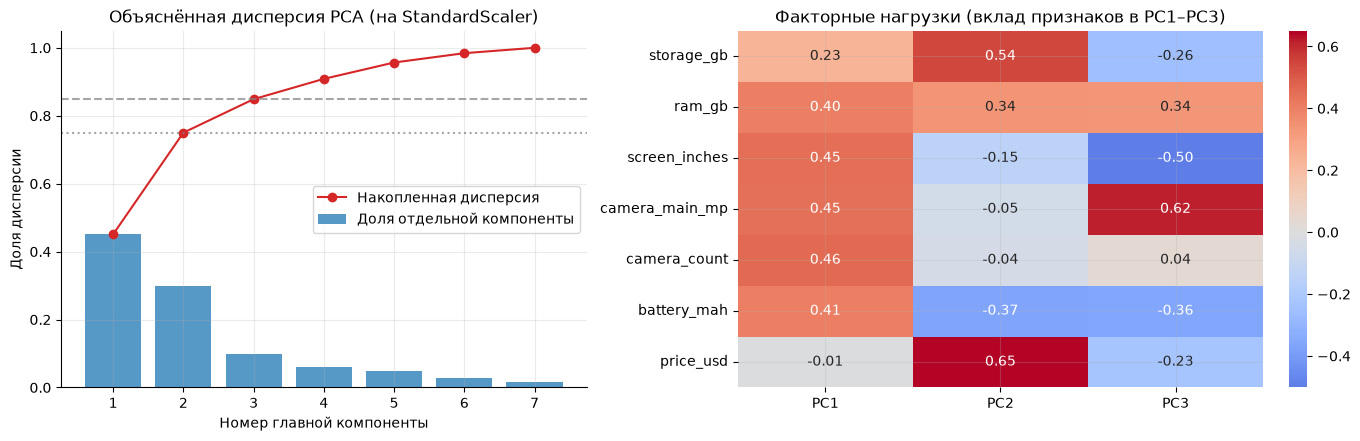

,Предобработка,Метод,Кластеров,"Шум, %",ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,StandardScaler + PCA(2),CustomKMeans (k-means++),4,0.0,0.501,0.525,0.525,0.771,0.771,0.470
1,StandardScaler + PCA(2),sklearn KMeans,4,0.0,0.501,0.525,0.525,0.771,0.771,0.470
2,StandardScaler + PCA(2),Agglomerative (ward),4,0.0,0.497,0.498,0.498,0.771,0.771,0.467
3,StandardScaler + PCA(2),"DBSCAN (eps=0.69, ms=5)",3,22.0,0.408,0.459,0.459,0.703,0.619,0.513
4,StandardScaler + PCA(3),CustomKMeans (k-means++),4,0.0,0.495,0.495,0.495,0.763,0.763,0.408
5,StandardScaler + PCA(3),sklearn KMeans,4,0.0,0.490,0.510,0.510,0.763,0.763,0.417
6,StandardScaler + PCA(3),Agglomerative (ward),4,0.0,0.553,0.570,0.570,0.805,0.805,0.402
7,StandardScaler + PCA(3),"DBSCAN (eps=1.04, ms=5)",3,16.1,0.423,0.504,0.504,0.729,0.644,0.425


In [8]:
pca_full = PCA(random_state=SEED).fit(X_std)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

pca_info = pd.DataFrame({
    'Компонента': [f'PC{i+1}' for i in range(len(evr))],
    'Доля дисперсии': evr,
    'Накопленная доля': cum_evr,
})
display(pca_info.round(4))

loadings = pd.DataFrame(
    pca_full.components_[:3].T,
    index=NUM_COLS,
    columns=['PC1', 'PC2', 'PC3'],
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), constrained_layout=True)
x_idx = np.arange(1, len(evr) + 1)
axes[0].bar(x_idx, evr, alpha=0.75, label='Доля отдельной компоненты')
axes[0].plot(x_idx, cum_evr, marker='o', color='tab:red', label='Накопленная дисперсия')
axes[0].axhline(0.75, color='gray', linestyle=':', alpha=0.7)
axes[0].axhline(0.85, color='gray', linestyle='--', alpha=0.7)
axes[0].set(title='Объяснённая дисперсия PCA (на StandardScaler)', xlabel='Номер главной компоненты', ylabel='Доля дисперсии', xticks=x_idx)
axes[0].legend()

sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Факторные нагрузки (вклад признаков в PC1–PC3)')
plt.show()

# Применяем все методы кластеризации на StandardScaler + PCA(2) и StandardScaler + PCA(3)
for n_comp, q_db in [(2, 0.75), (3, 0.80)]:
    prep_label = f'StandardScaler + PCA({n_comp})'
    X_pca = PCA(n_components=n_comp, random_state=SEED).fit_transform(X_std)

    ckm_p = CustomKMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit(X_pca)
    skm_p = KMeans(n_clusters=N_CLASSES, init='k-means++', n_init=20, random_state=SEED).fit(X_pca)
    ward_p = AgglomerativeClustering(n_clusters=N_CLASSES, linkage='ward').fit_predict(X_pca)

    kdist_p = k_distance_curve(X_pca, k=5)
    eps_p = float(np.quantile(kdist_p, q_db))
    db_p = DBSCAN(eps=eps_p, min_samples=5).fit_predict(X_pca)

    record_result(X_pca, ckm_p.labels_, 'CustomKMeans (k-means++)', prep_label)
    record_result(X_pca, skm_p.labels_, 'sklearn KMeans', prep_label)
    record_result(X_pca, ward_p, 'Agglomerative (ward)', prep_label)
    record_result(X_pca, db_p, f'DBSCAN (eps={eps_p:.2f}, ms=5)', prep_label)

pca_summary = pd.DataFrame([r for r in all_results if 'PCA' in r['Предобработка']])
display(pca_summary[['Предобработка', 'Метод', 'Кластеров', 'Шум, %', 'ARI', 'NMI', 'V-measure', 'Purity', 'Accuracy (Hungarian)', 'Silhouette']].round(3))

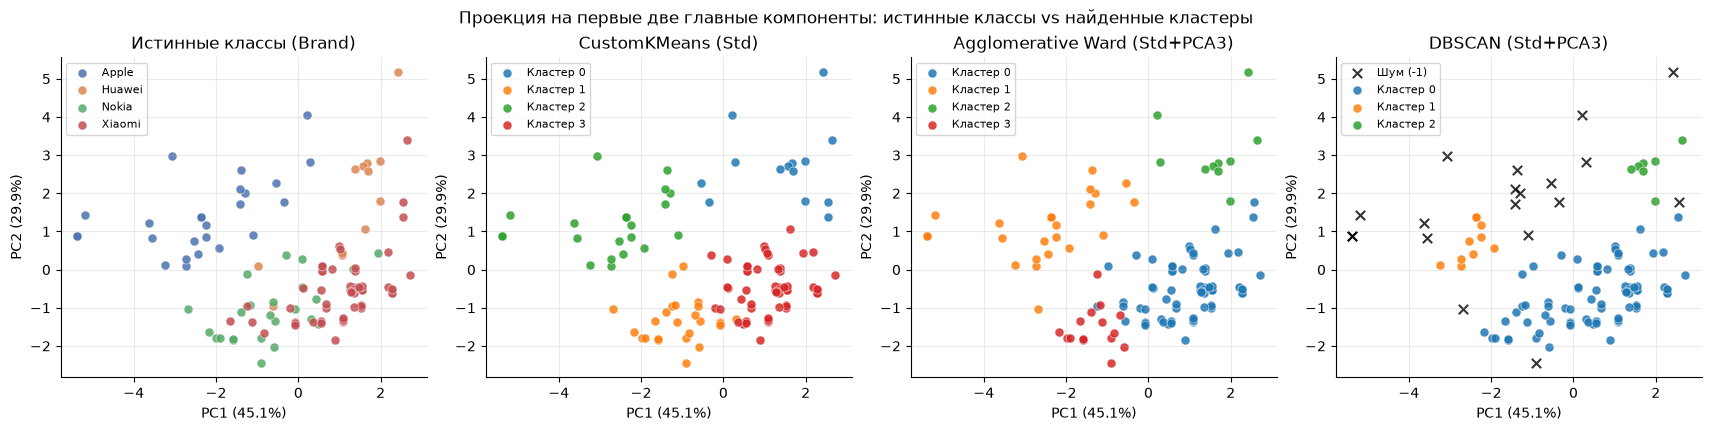

In [9]:
# Визуализация истинных брендов и результатов кластеризации в плоскости (PC1, PC2)
X_pca2 = PCA(n_components=2, random_state=SEED).fit_transform(X_std)
X_pca3 = PCA(n_components=3, random_state=SEED).fit_transform(X_std)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)

# 1. Истинные классы
for brand in SELECTED_BRANDS:
    mask = (data['Brand'].values == brand)
    axes[0].scatter(X_pca2[mask, 0], X_pca2[mask, 1], label=brand, color=palette[brand], s=42, alpha=0.85, edgecolor='white', linewidth=0.4)
axes[0].set(title='Истинные классы (Brand)', xlabel='PC1 (45.1%)', ylabel='PC2 (29.9%)')
axes[0].legend(fontsize=8)

# 2-4. Кластеры лучших конфигураций
plots = [
    (axes[1], saved_labels[('StandardScaler', 'CustomKMeans (k-means++)')], 'CustomKMeans (Std)'),
    (axes[2], saved_labels[('StandardScaler + PCA(3)', 'Agglomerative (ward)')], 'Agglomerative Ward (Std+PCA3)'),
    (axes[3], saved_labels[(
        'StandardScaler + PCA(3)',
        next(m for (p, m) in saved_labels if p == 'StandardScaler + PCA(3)' and m.startswith('DBSCAN'))
    )], 'DBSCAN (Std+PCA3)'),
]

cluster_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
for ax, lbls, title in plots:
    for cl in sorted(np.unique(lbls)):
        mask = (lbls == cl)
        if cl == -1:
            ax.scatter(X_pca2[mask, 0], X_pca2[mask, 1], marker='x', color='black', s=45, label='Шум (-1)', alpha=0.8)
        else:
            ax.scatter(X_pca2[mask, 0], X_pca2[mask, 1], color=cluster_colors[cl % len(cluster_colors)],
                       s=42, alpha=0.85, edgecolor='white', linewidth=0.4, label=f'Кластер {cl}')
    ax.set(title=title, xlabel='PC1 (45.1%)', ylabel='PC2 (29.9%)')
    ax.legend(fontsize=8)

fig.suptitle('Проекция на первые две главные компоненты: истинные классы vs найденные кластеры', fontsize=12)
plt.show()

**Вывод по уменьшению размерности (PCA):**
- Первые две главные компоненты объясняют **75.0%** общей дисперсии, первые три — **84.9%**:
  - `PC1` (45.1%) отражает «аппаратное оснащение Android-типа» (высокие положительные нагрузки у `camera_count` 0.46, `screen_inches` 0.45, `camera_main_mp` 0.45, `battery_mah` 0.41 и `ram_gb` 0.40 при почти нулевой нагрузке цены `-0.01`);
  - `PC2` (29.9%) отвечает за «премиальность и объём памяти при компактной батарее» (высокие положительные нагрузки у `price_usd` 0.65, `storage_gb` 0.54, `ram_gb` 0.34 и отрицательная у `battery_mah` `-0.37`), отделяя `Apple` и `Huawei` от бюджетных Android-моделей;
  - `PC3` (9.9%) противопоставляет высокое разрешение камеры (`camera_main_mp` 0.62) большому экрану и батарее (`screen_inches` `-0.50`, `battery_mah` `-0.36`), помогая разделять массовые `Xiaomi` и бюджетные `Nokia`.
- Снижение размерности с 7 до 3 компонент (`StandardScaler + PCA(3)`) заметно **улучшило иерархическую кластеризацию и DBSCAN**:
  - `AgglomerativeClustering (ward)` достиг лучшего результата во всей работе: **`ARI = 0.553`**, **`NMI = 0.570`**, **`Accuracy = 80.5%`** (против `ARI = 0.401` без PCA);
  - `DBSCAN` вырос с `ARI = 0.330` до **`ARI = 0.423`** (и `Silhouette` с 0.263 до 0.425), поскольку в 3-мерном пространстве расстояния между соседями более контрастны и проклятие размерности проявляется слабее;
  - `k-means` на `PCA(2)` сохранил практически то же качество (`ARI = 0.501`, `NMI = 0.525`), что и в полном 7-мерном стандартизированном пространстве (`ARI = 0.504`).

---
## 7. Итоговое сравнение всех экспериментов и выводы

,Предобработка,Метод,Кластеров,"Шум, %",ARI,NMI,V-measure,Purity,Accuracy (Hungarian),Silhouette
0,StandardScaler + PCA(3),Agglomerative (ward),4,0.0,0.553,0.570,0.570,0.805,0.805,0.402
1,StandardScaler,sklearn KMeans,4,0.0,0.504,0.519,0.519,0.771,0.771,0.324
2,StandardScaler,CustomKMeans (k-means++),4,0.0,0.504,0.519,0.519,0.771,0.771,0.324
3,StandardScaler + PCA(2),CustomKMeans (k-means++),4,0.0,0.501,0.525,0.525,0.771,0.771,0.470
4,StandardScaler + PCA(2),sklearn KMeans,4,0.0,0.501,0.525,0.525,0.771,0.771,0.470
5,StandardScaler + PCA(2),Agglomerative (ward),4,0.0,0.497,0.498,0.498,0.771,0.771,0.467
6,StandardScaler + PCA(3),CustomKMeans (k-means++),4,0.0,0.495,0.495,0.495,0.763,0.763,0.408
7,StandardScaler + PCA(3),sklearn KMeans,4,0.0,0.490,0.510,0.510,0.763,0.763,0.417
8,StandardScaler + PCA(3),"DBSCAN (eps=1.04, ms=5)",3,16.1,0.423,0.504,0.504,0.729,0.644,0.425
9,StandardScaler + PCA(2),"DBSCAN (eps=0.69, ms=5)",3,22.0,0.408,0.459,0.459,0.703,0.619,0.513


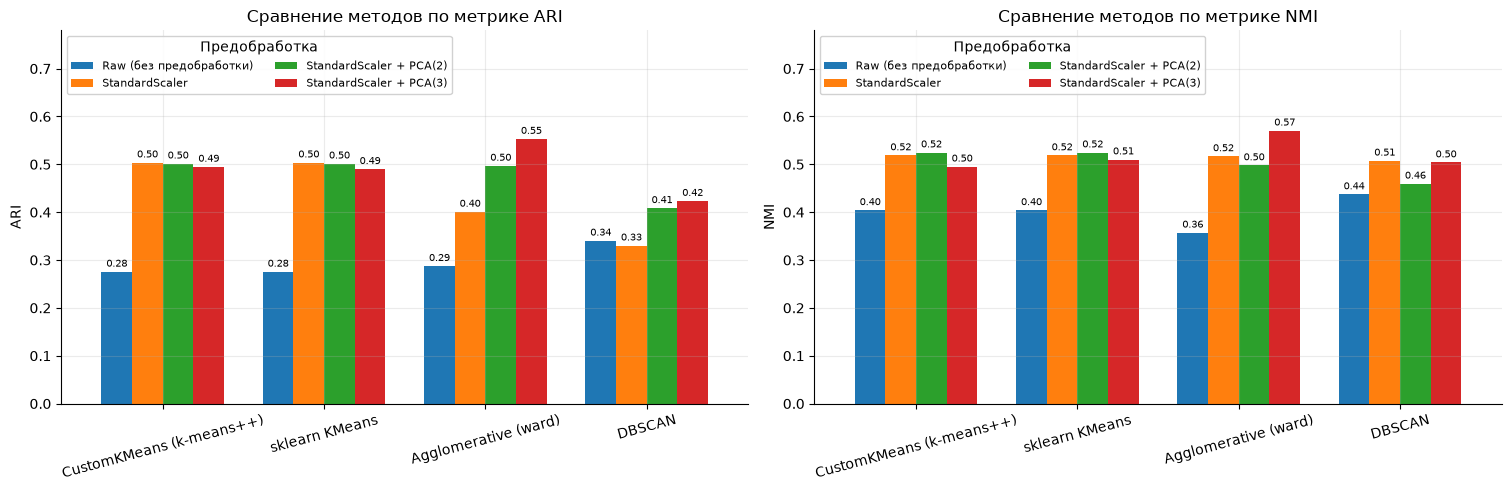

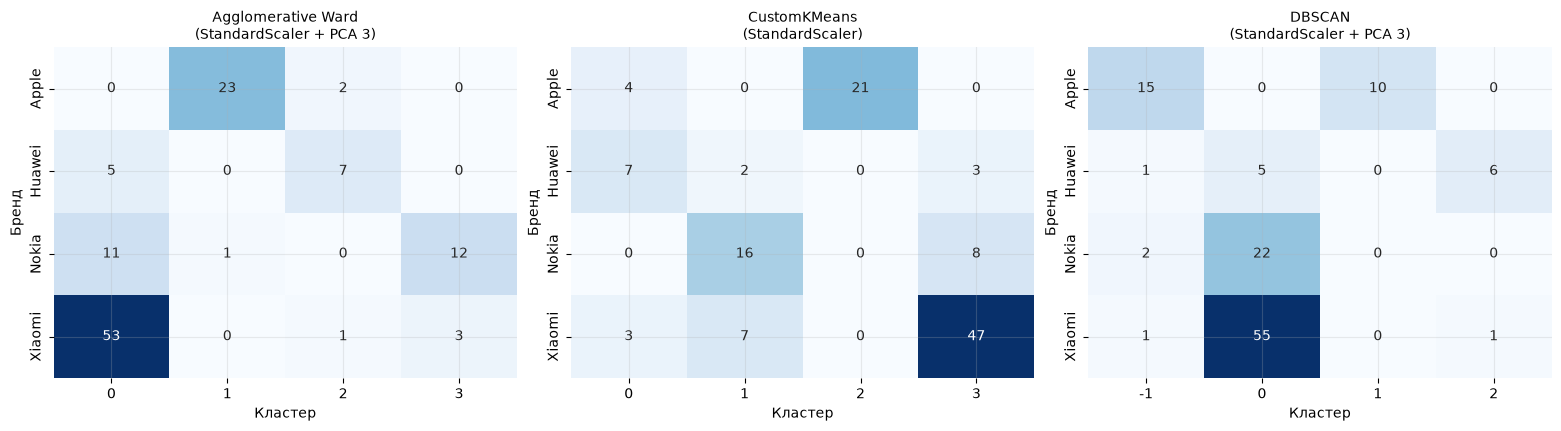

Объектов, попавших не в кластер своего бренда (Ward + Std + PCA3): 23 из 118 (19.5%)


,Brand,Model,dominant_brand,storage_gb,ram_gb,camera_main_mp,battery_mah,price_usd
17,Apple,iPhone 13 Pro Max,Huawei,256.0,6.0,12.0,4352.0,1299.0
24,Nokia,XR20,Xiaomi,128.0,6.0,48.0,4630.0,549.0
26,Nokia,5.4,Xiaomi,64.0,4.0,48.0,4000.0,249.0
27,Xiaomi,Mi 11 Ultra,Huawei,256.0,12.0,50.0,5000.0,1199.0
31,Nokia,G20,Xiaomi,64.0,4.0,48.0,5050.0,199.0
38,Nokia,G50,Xiaomi,64.0,4.0,48.0,5000.0,299.0
39,Xiaomi,Redmi 9 Activ,Nokia,64.0,4.0,13.0,5000.0,149.0
50,Xiaomi,Redmi 9i,Nokia,64.0,4.0,13.0,5000.0,139.0
54,Nokia,X20,Xiaomi,128.0,6.0,64.0,4470.0,449.0
57,Nokia,G20,Xiaomi,64.0,4.0,48.0,5050.0,199.0


In [10]:
results_df = pd.DataFrame(all_results)
# Упрощённое имя метода для группировки на графике
results_df['Семейство'] = results_df['Метод'].str.replace(r' \(eps=.*\)', '', regex=True)

display(
    results_df[['Предобработка', 'Метод', 'Кластеров', 'Шум, %', 'ARI', 'NMI', 'V-measure', 'Purity', 'Accuracy (Hungarian)', 'Silhouette']]
    .sort_values('ARI', ascending=False)
    .reset_index(drop=True)
    .round(3)
)

# Сводный график ARI и NMI по этапам предобработки
prep_order = [
    'Raw (без предобработки)',
    'StandardScaler',
    'StandardScaler + PCA(2)',
    'StandardScaler + PCA(3)',
]
method_order = ['CustomKMeans (k-means++)', 'sklearn KMeans', 'Agglomerative (ward)', 'DBSCAN']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
for ax, metric in zip(axes, ['ARI', 'NMI']):
    pivot = results_df.pivot(index='Семейство', columns='Предобработка', values=metric).loc[method_order, prep_order]
    pivot.plot(kind='bar', ax=ax, width=0.76)
    ax.set(title=f'Сравнение методов по метрике {metric}', xlabel='', ylabel=metric, ylim=(0, 0.78))
    ax.tick_params(axis='x', rotation=15)
    ax.legend(title='Предобработка', fontsize=8, loc='upper left', ncol=2, framealpha=0.9)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontsize=7, padding=2)
plt.show()

# Матрицы сопряжённости для трёх лучших конфигураций
db_pca3_key = next(m for (p, m) in saved_labels if p == 'StandardScaler + PCA(3)' and m.startswith('DBSCAN'))
top_configs = [
    ('Agglomerative Ward\n(StandardScaler + PCA 3)', saved_labels[('StandardScaler + PCA(3)', 'Agglomerative (ward)')]),
    ('CustomKMeans\n(StandardScaler)', saved_labels[('StandardScaler', 'CustomKMeans (k-means++)')]),
    ('DBSCAN\n(StandardScaler + PCA 3)', saved_labels[('StandardScaler + PCA(3)', db_pca3_key)]),
]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2), constrained_layout=True)
for ax, (title, lbls) in zip(axes, top_configs):
    ct = pd.crosstab(pd.Series(data['Brand'].values, name='Бренд'), pd.Series(lbls, name='Кластер'))
    sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(title, fontsize=10)
plt.show()

# Разбор пограничных смартфонов в лучшем разбиении (Ward + StandardScaler + PCA(3))
best_lbl = saved_labels[('StandardScaler + PCA(3)', 'Agglomerative (ward)')]
analysis_df = data.copy()
analysis_df['cluster'] = best_lbl
cluster_majority = analysis_df.groupby('cluster')['Brand'].agg(lambda s: s.value_counts().index[0]).to_dict()
analysis_df['dominant_brand'] = analysis_df['cluster'].map(cluster_majority)
mismatched = analysis_df[analysis_df['Brand'] != analysis_df['dominant_brand']]
print(f'Объектов, попавших не в кластер своего бренда (Ward + Std + PCA3): {len(mismatched)} из {len(analysis_df)} ({len(mismatched)/len(analysis_df):.1%})')
display(mismatched[['Brand', 'Model', 'dominant_brand', 'storage_gb', 'ram_gb', 'camera_main_mp', 'battery_mah', 'price_usd']].head(12))

### Итоговые выводы

1. **Постановка задачи и данные:** на базе датасета смартфонов `dataset.csv` из ЛР начала семестра была поставлена задача кластеризации без учителя для 4 брендов (`Apple`, `Huawei`, `Nokia`, `Xiaomi`, 118 объектов) по 7 числовым характеристикам (`storage_gb`, `ram_gb`, `screen_inches`, `camera_main_mp`, `camera_count`, `battery_mah`, `price_usd`). Для оценки соответствия кластеров исходным классам использованы внешние метрики `ARI` (основная), `NMI`, `V-measure`, `Purity`, `Cluster Accuracy` (венгерский алгоритм), а для проверки геометрии кластеров и подбора параметров без использования меток — `Silhouette Score` и k-distance график.

2. **Собственная реализация `CustomKMeans` vs `sklearn.cluster.KMeans`:**
   - Написанная на `numpy` реализация (`k-means++`, `n_init=20`, защита от пустых кластеров, проверка монотонности `WCSS`) даёт практически тождественные разбиения и значения `inertia_` по сравнению с `sklearn.cluster.KMeans` (на `Raw`, `StandardScaler` и `StandardScaler + PCA(2)` разбиения совпали полностью, `ARI = 1.000`).

3. **Роль предобработки (нормализация и PCA):**
   - **Нормализация дала наибольший прирост качества.** На исходных данных (`Raw`) масштаб `battery_mah` и `price_usd` подавлял остальные 5 признаков, поэтому `ARI` не превышал `0.275–0.340`. Применение `StandardScaler` подняло `ARI` для `k-means` с `0.275` до `0.504` (`Accuracy`: `56.8% → 77.1%`), а для `Agglomerative (ward)` — с `0.287` до `0.401`.
   - **PCA (3 главные компоненты, 84.9% дисперсии) дополнительно улучшил иерархическую и плотностную кластеризацию:** у `AgglomerativeClustering (ward)` `ARI` вырос до **`0.553`** (`NMI = 0.570`, `Accuracy = 80.5%` — лучший результат эксперимента), а у `DBSCAN` `ARI` увеличился с `0.330` до **`0.423`** за счёт устранения избыточной корреляции признаков и снижения размерности.

4. **Сравнение методов и предметный разбор ошибок:**
   - **Лучшие методы на данной задаче:** `AgglomerativeClustering (ward)` на `StandardScaler + PCA(3)` (`ARI = 0.553`) и `k-means` (`CustomKMeans` / `sklearn`) на `StandardScaler` (`ARI = 0.504`). Оба метода формируют компактные кластеры, хорошо согласующиеся с 4 целевыми брендами.
   - **Особенности и ограничения `DBSCAN`:** метод не требует задавать число кластеров заранее и на `StandardScaler + PCA(3)` выделил 3 плотных кластера — чистое ядро `Apple` (10 моделей), ядро Android-флагманов `Huawei` (6 моделей + 1 флагман `Xiaomi`) и объединённый массовый Android-кластер (`Xiaomi` + `Nokia`), отнеся 16.1% разреженных моделей (в основном крайние модели `Apple`: `iPhone SE`, `Mini`, `Pro Max`) к шуму (`-1`). Из-за разной плотности кластеров и плавного перехода между `Nokia` и `Xiaomi` единый порог `eps` не позволяет разделить эти два бренда.
   - **Почему идеальное совпадение (`ARI = 1.0`) принципиально недостижимо без меток бренда:** матрицы сопряжённости и список пограничных моделей показывают, что `Apple` отделяется почти идеально (23 из 25 устройств в одном кластере у Ward и 21 из 25 с чистотой 100% у k-means), тогда как **флагманы разных брендов физически похожи по характеристикам** (`Xiaomi Mi 11 Ultra` попадает к флагманам `Huawei`, старший `iPhone 13 Pro Max` с большим экраном и батареей 4352 мА·ч — в тот же флагманский кластер, а модели `Nokia G50` / `G20` с камерой 48 МП и батареей 5000 мА·ч — в массовый кластер `Xiaomi`). Это естественное свойство данных: кластеризация восстанавливает в первую очередь **технико-ценовые сегменты**, которые лишь частично совпадают с торговой маркой.